<a href="https://colab.research.google.com/github/dbustosh/Kiro/blob/main/IAyMR_20261119_Calibracion_Pose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p style="font-size:300%; background-color:#ffe6f0; color:#0044cc; text-align:center; line-height:80px; margin:0; padding:0;"> <b>Calibración de Cámara - Estimación de Pose</b> </p>

<p style="font-size:240%; background-color:#ffe6f0; color:#cc0000; text-align:center; line-height:60px; margin:0; padding:0;">
  <b>Inteligencia Artificial & Mini Robots</b>
</p>

<p style="font-size:200%; text-align:center; line-height:40px; margin:0;">
  <br><b>Prof. Flavio Prieto</b>
</p>

<p style="font-size:160%; text-align:center; line-height:25px; margin:0;">
  email: <a href="mailto:faprietoo@unal.edu.co">faprietoo@unal.edu.co</a>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  <br><b>DEPARTAMENTO DE INGENIERÍA MECÁNICA Y MECATRÓNICA</b>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  Facultad de Ingeniería
</p>

<p style="font-size:160%; text-align:center; line-height:30px; margin:0;">
  Universidad Nacional de Colombia – Sede Bogotá
</p>

<div style="text-align:center; margin-top:20px; margin-bottom:10px;">
  <img src="Fig/Escudo_UN.png" alt="Escudo UNAL" width="90" style="border:none;">
</div>



<hr style="border: 4px solid red;">

# CALIBRACIÓN DE CÁMARA


### Paso 1 — Sube tus fotos del tablero de ajedrez
Ejecuta la celda siguiente y selecciona las imágenes (patrón 7×7 esquinas internas, cuadrado de 17 mm).

In [ ]:
# ============================================================
# SUBIR LAS IMAGENES DEL TABLERO DE AJEDREZ
# ============================================================
# Ejecuta esta celda y selecciona tus fotos del tablero (jpg/png).
# Funciona tanto en Google Colab como en Jupyter local.
import os, shutil

calib_dir = "fig/Notebook/calib_images"
os.makedirs(calib_dir, exist_ok=True)

def _guardar(nombre, contenido):
    ruta = os.path.join(calib_dir, os.path.basename(nombre))
    with open(ruta, "wb") as f:
        f.write(contenido)
    return ruta

guardadas = []
try:
    # --- Entorno Google Colab ---
    from google.colab import files  # type: ignore
    print("Entorno: Google Colab. Selecciona tus imagenes del tablero...")
    subidas = files.upload()
    for nombre, contenido in subidas.items():
        guardadas.append(_guardar(nombre, contenido))
except ImportError:
    # --- Entorno Jupyter local: widget de carga ---
    try:
        import ipywidgets as widgets
        from IPython.display import display

        uploader = widgets.FileUpload(
            accept="image/*", multiple=True,
            description="Subir fotos"
        )
        boton = widgets.Button(description="Guardar imagenes", button_style="success")
        salida = widgets.Output()

        def _on_click(_):
            with salida:
                salida.clear_output()
                if not uploader.value:
                    print("Primero elige las imagenes con el boton 'Subir fotos'.")
                    return
                items = (uploader.value.values()
                         if isinstance(uploader.value, dict) else uploader.value)
                n = 0
                for item in items:
                    nombre = item.get("name") or item["metadata"]["name"]
                    contenido = item["content"]
                    contenido = (contenido.tobytes()
                                 if hasattr(contenido, "tobytes") else bytes(contenido))
                    ruta = _guardar(nombre, contenido)
                    guardadas.append(ruta)
                    n += 1
                print(f"{n} imagen(es) guardada(s) en '{calib_dir}'.")

        boton.on_click(_on_click)
        print("Entorno: Jupyter local. Sube tus fotos y pulsa 'Guardar imagenes'.")
        display(widgets.VBox([uploader, boton, salida]))
    except ImportError:
        print("No hay widget de carga disponible en este entorno.")
        print(f"Copia manualmente tus fotos en la carpeta: '{calib_dir}/'")

if guardadas:
    print("\nImagenes guardadas:")
    for g in guardadas:
        print("  -", g)


In [ ]:
import cv2
import numpy as np
import glob
import os
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Parametros del patron de calibracion
# ------------------------------------------------------------
# Tablero de ajedrez de 8x8 casillas  ->  7x7 esquinas internas.
chessboard_size = (7, 7)   # (columnas, filas) de esquinas internas
square_size = 17.0         # Tamano real de cada cuadrado en mm

# ------------------------------------------------------------
# Puntos 3D del patron en coordenadas del mundo (Z = 0)
# ------------------------------------------------------------
objp = np.zeros((chessboard_size[0] * chessboard_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:chessboard_size[0], 0:chessboard_size[1]].T.reshape(-1, 2)
objp *= square_size

objpoints = []  # puntos 3D en el mundo real
imgpoints = []  # puntos 2D detectados en la imagen

# ------------------------------------------------------------
# Cargar las imagenes que subiste en la celda anterior
# ------------------------------------------------------------
images = sorted(glob.glob(os.path.join(calib_dir, "*.jpg")) +
                glob.glob(os.path.join(calib_dir, "*.jpeg")) +
                glob.glob(os.path.join(calib_dir, "*.png")))

if len(images) == 0:
    raise FileNotFoundError(
        "No hay imagenes cargadas. Ejecuta primero la celda de 'SUBIR LAS IMAGENES' "
        "y selecciona tus fotos del tablero."
    )

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
find_flags = (cv2.CALIB_CB_ADAPTIVE_THRESH +
              cv2.CALIB_CB_NORMALIZE_IMAGE +
              cv2.CALIB_CB_FAST_CHECK)

gray = None
detectadas = 0

for fname in images:
    img = cv2.imread(fname)
    if img is None:
        print(f"No se pudo leer: {fname}")
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ret, corners = cv2.findChessboardCorners(gray, chessboard_size, find_flags)
    if not ret and hasattr(cv2, "findChessboardCornersSB"):
        ret, corners = cv2.findChessboardCornersSB(gray, chessboard_size, None)

    if ret:
        detectadas += 1
        objpoints.append(objp)
        corners2 = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
        imgpoints.append(corners2)

        vis = img.copy()
        cv2.drawChessboardCorners(vis, chessboard_size, corners2, ret)
        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"Esquinas detectadas: {os.path.basename(fname)}")
        plt.axis("off")
        plt.show()
    else:
        print(f"No se detectaron esquinas en: {os.path.basename(fname)}")

print(f"\nImagenes con esquinas detectadas: {detectadas} de {len(images)}")


In [ ]:
# ------------------------------------------------------------
# Calibracion de camara
# ------------------------------------------------------------
if len(objpoints) < 3:
    raise RuntimeError(
        "No hay suficientes imagenes validas para calibrar la camara. "
        "Se necesitan al menos 3 imagenes con el patron 7x7 detectado. "
        "Revisa la iluminacion, que el tablero este plano y bien enfocado."
    )

ret, K, distCoeffs, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, gray.shape[::-1], None, None
)

print("\nCalibracion completada correctamente.")
print(f"\nError de reproyeccion RMS devuelto por cv2.calibrateCamera: {ret:.4f} px")
print("\nMatriz intrinseca (K):\n", K)
print("\nCoeficientes de distorsion [k1, k2, p1, p2, k3]:\n", distCoeffs.ravel())

# ------------------------------------------------------------
# R, t y P para la primera imagen
# ------------------------------------------------------------
R, _ = cv2.Rodrigues(rvecs[0])   # vector de rotacion -> matriz de rotacion
t = tvecs[0].reshape(3, 1)       # vector de traslacion como columna
Rt = np.hstack((R, t))           # [R | t]
P = K @ Rt                       # matriz de proyeccion P = K [R | t]

print("\nMatriz de rotacion (R):\n", R)
print("\nVector de traslacion (t):\n", t)
print("\nMatriz de proyeccion (P = K [R | t]):\n", P)

# ------------------------------------------------------------
# Error de reproyeccion promedio (verificacion)
# ------------------------------------------------------------
error_total = 0.0
for i in range(len(objpoints)):
    proy, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, distCoeffs)
    error = cv2.norm(imgpoints[i], proy, cv2.NORM_L2) / len(proy)
    error_total += error
print(f"\nError de reproyeccion promedio: {error_total / len(objpoints):.4f} px")


In [ ]:
# ------------------------------------------------------------
# Corregir la distorsion en una de las imagenes de calibracion
# ------------------------------------------------------------
img = cv2.imread(images[0])
h, w = img.shape[:2]

newK, roi = cv2.getOptimalNewCameraMatrix(K, distCoeffs, (w, h), 1, (w, h))
undistorted = cv2.undistort(img, K, distCoeffs, None, newK)

# Recortar al ROI valido
x, y, rw, rh = roi
if rw > 0 and rh > 0:
    undistorted = undistorted[y:y + rh, x:x + rw]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Imagen original (con distorsion)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(undistorted, cv2.COLOR_BGR2RGB))
plt.title("Imagen corregida (sin distorsion)")
plt.axis("off")

plt.tight_layout()
plt.show()


<hr style="border: 4px solid red;">

# Distorsión radial

### Matriz intrínseca `camera_matrix`

Representa los parámetros internos de la cámara:

\[
K =
\begin{bmatrix}
f_x & 0   & c_x \\
0   & f_y & c_y \\
0   & 0   & 1
\end{bmatrix}
\]

donde \( f_x, f_y \) son las **longitudes focales** y \( (c_x, c_y) \) es el **centro óptico**.

---

### Coeficientes de distorsión `dist_coeffs`

\[
[k_1, k_2, p_1, p_2, k_3]
\]

- \( k_1, k_2, k_3 \): **distorsión radial**  
- \( p_1, p_2 \): **distorsión tangencial**

---

### Corrección aplicada por OpenCV

El modelo de corrección de distorsión es:

\[
\begin{aligned}
x_{\text{corr}} &= x \left( 1 + k_1 r^2 + k_2 r^4 + k_3 r^6 \right)
+ 2 p_1 x y + p_2 (r^2 + 2x^2), \\[6pt]
y_{\text{corr}} &= y \left( 1 + k_1 r^2 + k_2 r^4 + k_3 r^6 \right)
+ p_1 (r^2 + 2y^2) + 2 p_2 x y,
\end{aligned}
\]

donde:

\[
r^2 = x^2 + y^2.
\]


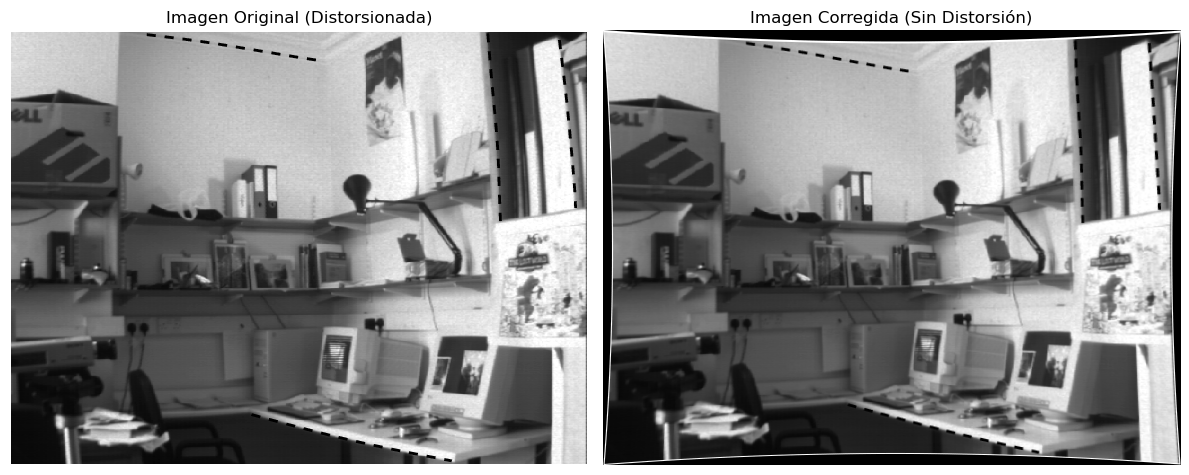

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------------
# 1. Cargar imagen (distorsionada)
# --------------------------------------------------------
img_path = "fig/Latex/img26.png"  # Cambia la ruta según tu imagen
img = cv2.imread(img_path)
if img is None:
    raise FileNotFoundError("No se encontró la imagen. Verifica la ruta.")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# --------------------------------------------------------
# 2. Definir parámetros intrínsecos y de distorsión
# --------------------------------------------------------
# Supón una cámara genérica (estos valores deben provenir de la calibración real)
h, w = img.shape[:2]
fx, fy = 800, 800   # Longitudes focales (en píxeles)
cx, cy = w / 2, h / 2  # Centro óptico (aprox. centro de la imagen)

camera_matrix = np.array([
    [fx, 0, cx],
    [0, fy, cy],
    [0,  0,  1]
])

# Parámetros de distorsión: [k1, k2, p1, p2, k3]
dist_coeffs = np.array([-0.35, 0.15, 0.001, 0.001, -0.05])

# --------------------------------------------------------
# 3. Calcular la corrección de la distorsión
# --------------------------------------------------------
new_camera_mtx, roi = cv2.getOptimalNewCameraMatrix(camera_matrix, dist_coeffs, (w, h), 1, (w, h))
img_undistorted = cv2.undistort(img, camera_matrix, dist_coeffs, None, new_camera_mtx)

# --------------------------------------------------------
# 4. Mostrar resultados
# --------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img)
axes[0].set_title("Imagen Original (Distorsionada)")
axes[0].axis("off")

axes[1].imshow(img_undistorted)
axes[1].set_title("Imagen Corregida (Sin Distorsión)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


<hr style="border: 4px solid red;">